### **03_Image_Features — PRML Assignment 8**

Comparing GMM, LDA, KNN, and SVM on 36-dimensional extracted image features (Dataset2).

### **Imports**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from src import GMMClassifier, LDA, KNN, SVM, PCA, StandardScaler

### **Load Data**

In [2]:
data_dir = "../Datasets/ImageFeaturesDataset/Dataset2"

X_train = np.loadtxt(f"{data_dir}/train_data.csv", delimiter=",")
y_train = np.loadtxt(f"{data_dir}/train_label.csv", delimiter=",").astype(int).ravel()
X_val = np.loadtxt(f"{data_dir}/val_data.csv", delimiter=",")
y_val = np.loadtxt(f"{data_dir}/val_label.csv", delimiter=",").astype(int).ravel()
X_test = np.loadtxt(f"{data_dir}/test_data.csv", delimiter=",")
y_test = np.loadtxt(f"{data_dir}/test_label.csv", delimiter=",").astype(int).ravel()

print("Train:", X_train.shape, "Validation:", X_val.shape, "Test:", X_test.shape)
print("Class counts in train:", np.unique(y_train, return_counts=True))

Train: (2000, 36) Validation: (500, 36) Test: (500, 36)
Class counts in train: (array([0, 1, 2, 3, 4]), array([400, 400, 400, 400, 400], dtype=int64))


### **Feature Standardization**

In [ ]:
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

# Setup classes and results dictionary for evaluation
classes = np.unique(y_train)
label_to_idx = {int(c): i for i, c in enumerate(classes)}
results = {}

### **Classifiers on Original Features**


### **1. Gaussian Mixture Model (GMM)**


In [ ]:
# Train and evaluate GMM on original features
gmm = GMMClassifier(K=3, reg=1e-3)
gmm.fit(X_train_s, y_train)

val_pred = gmm.predict(X_val_s)
test_pred = gmm.predict(X_test_s)

val_acc = float(np.mean(y_val == val_pred))
test_acc = float(np.mean(y_test == test_pred))
results["GMM original"] = (val_acc, test_acc)

cm = np.zeros((len(classes), len(classes)), dtype=int)
for t, p in zip(y_test, test_pred):
    cm[label_to_idx[int(t)], label_to_idx[int(p)]] += 1

print(f"GMM original     | Validation: {val_acc:.4f} | Test: {test_acc:.4f}")
print("Confusion matrix:\n", cm)

### **2. Linear Discriminant Analysis (LDA)**


In [ ]:
# Train and evaluate LDA on original features
lda = LDA()
lda.fit(X_train_s, y_train)

val_pred = lda.predict(X_val_s)
test_pred = lda.predict(X_test_s)

val_acc = float(np.mean(y_val == val_pred))
test_acc = float(np.mean(y_test == test_pred))
results["LDA original"] = (val_acc, test_acc)

cm = np.zeros((len(classes), len(classes)), dtype=int)
for t, p in zip(y_test, test_pred):
    cm[label_to_idx[int(t)], label_to_idx[int(p)]] += 1

print(f"LDA original     | Validation: {val_acc:.4f} | Test: {test_acc:.4f}")
print("Confusion matrix:\n", cm)

### **3. K-Nearest Neighbours (KNN)**


In [ ]:
# Train and evaluate KNN on original features
knn = KNN(k=5)
knn.fit(X_train_s, y_train)

val_pred = knn.predict(X_val_s)
test_pred = knn.predict(X_test_s)

val_acc = float(np.mean(y_val == val_pred))
test_acc = float(np.mean(y_test == test_pred))
results["KNN original"] = (val_acc, test_acc)

cm = np.zeros((len(classes), len(classes)), dtype=int)
for t, p in zip(y_test, test_pred):
    cm[label_to_idx[int(t)], label_to_idx[int(p)]] += 1

print(f"KNN original     | Validation: {val_acc:.4f} | Test: {test_acc:.4f}")
print("Confusion matrix:\n", cm)

### **4. Support Vector Machine (SVM)**


In [ ]:
# Train and evaluate SVM on original features
svm = SVM(kernel="rbf", C=1.0, max_train=1500)
svm.fit(X_train_s, y_train)

val_pred = svm.predict(X_val_s)
test_pred = svm.predict(X_test_s)

val_acc = float(np.mean(y_val == val_pred))
test_acc = float(np.mean(y_test == test_pred))
results["SVM original"] = (val_acc, test_acc)

cm = np.zeros((len(classes), len(classes)), dtype=int)
for t, p in zip(y_test, test_pred):
    cm[label_to_idx[int(t)], label_to_idx[int(p)]] += 1

print(f"SVM original     | Validation: {val_acc:.4f} | Test: {test_acc:.4f}")
print("Confusion matrix:\n", cm)

### **Dimensionality Reduction with PCA**

In [6]:
K = 12
pca = PCA(n_components=K).fit(X_train_s)
X_train_p = pca.transform(X_train_s)
X_val_p = pca.transform(X_val_s)
X_test_p = pca.transform(X_test_s)

print(f"Retained variance with K={K}:", round(float(pca.explained_variance_ratio_.sum()), 4))

Retained variance with K=12: 0.6941


### **Classifiers on PCA Features**


### **1. GMM on PCA Features**


In [ ]:
# Train and evaluate GMM on PCA features
gmm_p = GMMClassifier(K=3, reg=1e-3)
gmm_p.fit(X_train_p, y_train)

val_pred = gmm_p.predict(X_val_p)
test_pred = gmm_p.predict(X_test_p)

val_acc = float(np.mean(y_val == val_pred))
test_acc = float(np.mean(y_test == test_pred))
results["GMM PCA"] = (val_acc, test_acc)

cm = np.zeros((len(classes), len(classes)), dtype=int)
for t, p in zip(y_test, test_pred):
    cm[label_to_idx[int(t)], label_to_idx[int(p)]] += 1

print(f"GMM PCA          | Validation: {val_acc:.4f} | Test: {test_acc:.4f}")
print("Confusion matrix:\n", cm)

### **2. LDA on PCA Features**


In [ ]:
# Train and evaluate LDA on PCA features
lda_p = LDA()
lda_p.fit(X_train_p, y_train)

val_pred = lda_p.predict(X_val_p)
test_pred = lda_p.predict(X_test_p)

val_acc = float(np.mean(y_val == val_pred))
test_acc = float(np.mean(y_test == test_pred))
results["LDA PCA"] = (val_acc, test_acc)

cm = np.zeros((len(classes), len(classes)), dtype=int)
for t, p in zip(y_test, test_pred):
    cm[label_to_idx[int(t)], label_to_idx[int(p)]] += 1

print(f"LDA PCA          | Validation: {val_acc:.4f} | Test: {test_acc:.4f}")
print("Confusion matrix:\n", cm)

### **3. KNN on PCA Features**


In [ ]:
# Train and evaluate KNN on PCA features
knn_p = KNN(k=5)
knn_p.fit(X_train_p, y_train)

val_pred = knn_p.predict(X_val_p)
test_pred = knn_p.predict(X_test_p)

val_acc = float(np.mean(y_val == val_pred))
test_acc = float(np.mean(y_test == test_pred))
results["KNN PCA"] = (val_acc, test_acc)

cm = np.zeros((len(classes), len(classes)), dtype=int)
for t, p in zip(y_test, test_pred):
    cm[label_to_idx[int(t)], label_to_idx[int(p)]] += 1

print(f"KNN PCA          | Validation: {val_acc:.4f} | Test: {test_acc:.4f}")
print("Confusion matrix:\n", cm)

### **4. SVM on PCA Features**


In [ ]:
# Train and evaluate SVM on PCA features
svm_p = SVM(kernel="rbf", C=1.0, max_train=1500)
svm_p.fit(X_train_p, y_train)

val_pred = svm_p.predict(X_val_p)
test_pred = svm_p.predict(X_test_p)

val_acc = float(np.mean(y_val == val_pred))
test_acc = float(np.mean(y_test == test_pred))
results["SVM PCA"] = (val_acc, test_acc)

cm = np.zeros((len(classes), len(classes)), dtype=int)
for t, p in zip(y_test, test_pred):
    cm[label_to_idx[int(t)], label_to_idx[int(p)]] += 1

print(f"SVM PCA          | Validation: {val_acc:.4f} | Test: {test_acc:.4f}")
print("Confusion matrix:\n", cm)

### **Results Comparison**

GMM original     | Validation: 0.4340 | Test: 0.4420
LDA original     | Validation: 0.4380 | Test: 0.4320
KNN original     | Validation: 0.4340 | Test: 0.4160
SVM original     | Validation: 0.5040 | Test: 0.5160
GMM PCA          | Validation: 0.4320 | Test: 0.4780
LDA PCA          | Validation: 0.4400 | Test: 0.4420
KNN PCA          | Validation: 0.4060 | Test: 0.4180
SVM PCA          | Validation: 0.5040 | Test: 0.4960


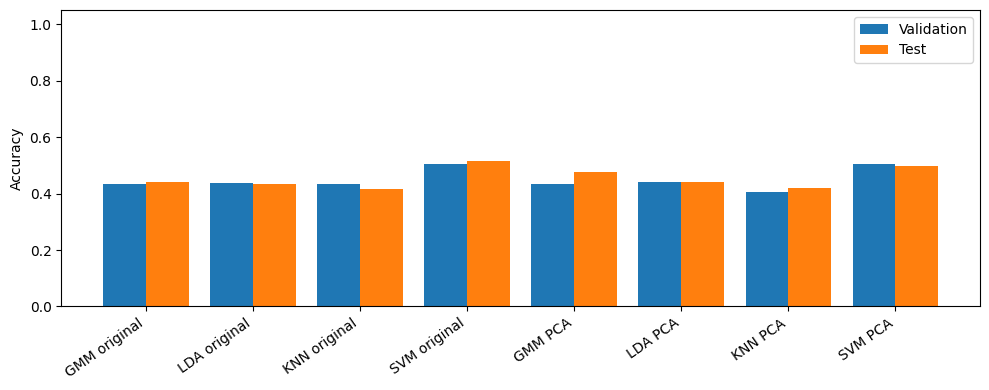

In [8]:
for name, (val_acc, test_acc) in results.items():
    print(f"{name:16s} | Validation: {val_acc:.4f} | Test: {test_acc:.4f}")

names = list(results.keys())
x_pos = np.arange(len(names))

plt.figure(figsize=(10, 4))
plt.bar(x_pos - 0.2, [results[n][0] for n in names], width=0.4, label="Validation")
plt.bar(x_pos + 0.2, [results[n][1] for n in names], width=0.4, label="Test")
plt.xticks(x_pos, names, rotation=35, ha="right")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.show()

### **Observations and Inferences**

- On pre-extracted multi-class features, SVM with RBF kernel achieves the highest accuracy.
- Top-12 PCA components capture the dominant directions without significant performance drops.